# Maintain Velocity Gait Analysis (Touch Sensors)

This notebook loads checkpoints trained using maintain_velocity task transfer,
generates rollouts, and performs gait analysis using **touch sensors** instead of contact detection:
- Video rendering
- Touch sensor data extraction (palm_L, palm_R, sole_L, sole_R)
- Force plots over time
- Threshold-based stance detection
- Gait diagram plotting

## Imports & Environment Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import json
from pathlib import Path

import imageio
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import orbax.checkpoint as ocp
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
from scipy.signal import medfilt

from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)

# %matplotlib inline
# %config InlineBackend.figure_format='retina'

# mpl.rcParams["figure.facecolor"] = "w"
# mpl.rcParams["figure.dpi"] = 150
# mpl.rcParams["savefig.dpi"] = 600
# mpl.rcParams["savefig.transparent"] = True
# mpl.rcParams["font.size"] = 8
# mpl.rcParams["font.family"] = "sans-serif"
# mpl.rcParams["font.sans-serif"] = ["Arial"]

## Configuration

Set the checkpoint path and other parameters here.

In [2]:
# Checkpoint path - UPDATE THIS to your checkpoint
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260209_092637_878648"
CHECKPOINT_STEP = 2  # None = latest step

NAME = "S3e-1"

# Rollout parameters
EPISODE_LENGTH = 1000  # Number of steps to roll out
SEED = 0

# Rendering parameters
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50

# Output directory
OUTPUT_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/{NAME}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint

Load the maintain_velocity checkpoint and determine the training mode.

In [3]:
# Load metadata to get config and determine mode
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
training_metadata = ckpt_info["training_metadata"]
ckpt_step = ckpt_info["step"]

mode = config["mode"]
ckpt_cfg = config["checkpoint_config"]

print(f"Loaded checkpoint at step: {ckpt_step}")
print(f"Training mode: {mode}")
print(f"Training metadata: {training_metadata}")

Loaded checkpoint at step: 2
Training mode: prior_decoder
Training metadata: {'completed_timesteps': 30801920, 'eval_step': 2, 'wandb_run_id': 'New3_S0.3_prior_decoder_260209_092637_878648', 'run_id': '260209_092637_878648', 'mode': 'prior_decoder'}


In [4]:
# Load frozen networks from the prior checkpoint embedded in the task transfer checkpoint
prior_checkpoint_path = config["checkpoint"]["path"]
prior_checkpoint_step = config["checkpoint"]["step"]

print(f"Loading frozen networks from prior checkpoint: {prior_checkpoint_path}")

(
    encoder_params,
    prior_params,
    decoder_params,
    normalizer_params,
    _,
) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

print(f"Latent size: {latent_size}")
print(f"Proprio size: {proprio_size}")
print(f"Action size: {action_size}")

Loading frozen networks from prior checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
Latent size: 16
Proprio size: 277
Action size: 38


## Create Environment

Create the maintain_velocity environment with the appropriate wrapper based on training mode.

In [5]:
# Create environment config from checkpoint
env_cfg = maintain_velocity.default_config()

# Set XML variant
xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.init_z = config["env"]["init_z"]
env_cfg.target_speed = config["env"]["target_speed"]

print(f"XML variant: {xml_variant}")
print(f"MuJoCo impl: {env_cfg.mujoco_impl}")
print(f"ctrl_dt: {env_cfg.ctrl_dt}")
print(f"Target speed: {env_cfg.target_speed}")

XML variant: no-tail-collisions
MuJoCo impl: warp
ctrl_dt: 0.01
Target speed: 0.3


In [6]:
# Create decoder inference function
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# Create base environment
base_env = maintain_velocity.MaintainVelocity(config=env_cfg)

# Wrap based on mode
if mode == "decoder_only":
    env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
elif mode == "scratch":
    env = FlatObsWrapper(base_env)
elif mode == "prior_decoder":
    prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
    env = PriorDecoderHighLevelWrapper(
        base_env,
        prior_fn,
        decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=config["prior_decoder"]["deterministic_prior"],
        noise_logvar=config["prior_decoder"]["noise_logvar"],
    )
else:
    raise ValueError(f"Unknown mode: {mode}")

print(f"Created wrapped environment for mode: {mode}")
print(f"Action size (policy outputs): {env.action_size}")

Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Created wrapped environment for mode: prior_decoder
Action size (policy outputs): 16


## Load Policy Parameters and Create Inference Function

In [7]:
# Create JIT-compiled reset and step functions
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

# Get observation shape from a reset
rng = jax.random.PRNGKey(0)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]

print(f"Observation size: {obs_size}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 15.64 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 5.72 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 5.02 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 6.30 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 9.05 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 5.13 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 4.83 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 6.06 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor ca6ca3f load on device 'cuda:0' took

E0223 09:58:24.680511  856855 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.181), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=47}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0223 09:58:39.200427  856651 slow_operation_alarm.cc:140] The operation took 15.520009222s
Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.181), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=47}

This isn't necessarily a bug

Observation size: 331


In [8]:
# Create network factory and build abstract params for loading
normalize = running_statistics.normalize
policy_action_size = env.action_size

if mode == "scratch":
    task_obs_size = obs_size - proprio_size
    decoder_hidden_layer_sizes = tuple(
        ckpt_cfg["network_config"]["decoder_layer_sizes"]
    )

    def network_factory(*args, **kwargs):
        return make_scratch_ppo_networks(
            task_obs_size=task_obs_size,
            proprio_size=proprio_size,
            action_size=action_size,
            latent_size=latent_size,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )

    dummy_net = network_factory()
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
else:
    network_factory = functools.partial(
        ppo_networks.make_ppo_networks,
        policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
        value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
    )

    dummy_net = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)

abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

# Load trained parameters
brax_params = load_task_transfer_brax_params(
    CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
)

print("Loaded policy parameters")

Loaded policy parameters


In [9]:
# Create inference function
if mode == "scratch":
    ppo_network = network_factory()
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

else:
    ppo_network = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}


jit_inference_fn = jax.jit(inference_fn)
print("Created inference function")

Created inference function


## Generate Rollout

In [10]:
# Generate rollout following pattern from logging.py
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

print(f"Generating rollout with {EPISODE_LENGTH} steps...")
for i in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)

    if (i + 1) % 100 == 0:
        print(f"  Step {i + 1}/{EPISODE_LENGTH}")

print(f"Rollout complete! {len(rollout)} states collected.")

Generating rollout with 1000 steps...
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 1.90 ms  (cached)
  Step 100/1000
  Step 200/1000
  Step 300/1000
  Step 400/1000
  Step 500/1000
  Step 600/1000
  Step 700/1000
  Step 800/1000
  Step 900/1000
  Step 1000/1000
Rollout complete! 1001 states collected.


## Save Rollout

In [47]:
import numpy as np
from pathlib import Path

ROLLOUT_SAVE_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/{NAME}"
)
ROLLOUT_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Extract state arrays to numpy
rollout_data = {
    "qpos": np.array([np.array(s.data.qpos) for s in rollout]),
    "qvel": np.array([np.array(s.data.qvel) for s in rollout]),
    "xpos": np.array([np.array(s.data.xpos) for s in rollout]),
    "sensordata": np.array([np.array(s.data.sensordata) for s in rollout]),
    "obs": np.array([np.array(s.obs) for s in rollout]),
    "reward": np.array([np.array(s.reward) for s in rollout]),
    "done": np.array([np.array(s.done) for s in rollout]),
}

run_id = Path(CHECKPOINT_PATH).name
save_path = ROLLOUT_SAVE_DIR / f"rollout_{NAME}_step{ckpt_step}_seed{SEED}_{run_id}.npz"
np.savez_compressed(save_path, **rollout_data)
print(f"Saved rollout to {save_path} ({save_path.stat().st_size / 1e6:.1f} MB)")

Saved rollout to /home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/S3e-1/rollout_S3e-1_step2_seed0_260209_092637_878648.npz (2.4 MB)


## Load previous rollout

In [10]:
from types import SimpleNamespace

ROLLOUT_SAVE_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/{NAME}"
)
run_id = Path(CHECKPOINT_PATH).name
save_path = ROLLOUT_SAVE_DIR / f"rollout_{NAME}_step{ckpt_step}_seed{SEED}_{run_id}.npz"

print(f"Loading rollout from {save_path}")
loaded = np.load(save_path)

# Get default values for fields needed by renderer but not saved in npz
_ref_state = jit_reset(jax.random.PRNGKey(99))
_default_mocap_pos = np.array(_ref_state.data.mocap_pos)
_default_mocap_quat = np.array(_ref_state.data.mocap_quat)
_default_xfrc = np.zeros_like(np.array(_ref_state.data.xfrc_applied))

# Reconstruct rollout as list of state-like objects
rollout = []
for i in range(len(loaded["qpos"])):
    data = SimpleNamespace(
        qpos=loaded["qpos"][i],
        qvel=loaded["qvel"][i],
        xpos=loaded["xpos"][i],
        sensordata=loaded["sensordata"][i],
        mocap_pos=_default_mocap_pos,
        mocap_quat=_default_mocap_quat,
        xfrc_applied=_default_xfrc,
    )
    state = SimpleNamespace(
        data=data,
        obs=loaded["obs"][i],
        reward=loaded["reward"][i],
        done=loaded["done"][i],
    )
    rollout.append(state)

num_timesteps = len(rollout)
print(f"Loaded {num_timesteps} states")
print(f"  qpos shape: {loaded['qpos'].shape}")
print(f"  sensordata shape: {loaded['sensordata'].shape}")

Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/S3e-1/rollout_S3e-1_step2_seed0_260209_092637_878648.npz
Loaded 1001 states
  qpos shape: (1001, 74)
  sensordata shape: (1001, 16)


## Render Video

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_profile-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_front_L-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_front_R-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_hind_L-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_hind_R-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

## Extract Touch Sensor Data

Extract and plot the touch sensor readings (palm_L, palm_R, sole_L, sole_R) throughout the rollout.

In [11]:
# Get the MuJoCo model for sensor lookups
unwrapped_env = env
while hasattr(unwrapped_env, "_env") or hasattr(unwrapped_env, "env"):
    if hasattr(unwrapped_env, "_env"):
        unwrapped_env = unwrapped_env._env
    elif hasattr(unwrapped_env, "env"):
        unwrapped_env = unwrapped_env.env

mj_model = unwrapped_env.mj_model

# Find touch sensor indices in sensordata
touch_sensors = {}
print("Touch sensors found:")
for i in range(mj_model.nsensor):
    name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_SENSOR, i)
    if name and ("palm" in name.lower() or "sole" in name.lower()):
        sensor_adr = mj_model.sensor_adr[i]
        sensor_dim = mj_model.sensor_dim[i]
        touch_sensors[name] = {"idx": sensor_adr, "dim": sensor_dim}
        print(f"  {name}: sensordata[{sensor_adr}]")

# Define sensor indices for easy access
PALM_L_IDX = touch_sensors.get("palm_L-rodent", {}).get("idx", 9)
PALM_R_IDX = touch_sensors.get("palm_R-rodent", {}).get("idx", 10)
SOLE_L_IDX = touch_sensors.get("sole_L-rodent", {}).get("idx", 11)
SOLE_R_IDX = touch_sensors.get("sole_R-rodent", {}).get("idx", 12)

print(
    f"\nSensor indices: palm_L={PALM_L_IDX}, palm_R={PALM_R_IDX}, sole_L={SOLE_L_IDX}, sole_R={SOLE_R_IDX}"
)

Touch sensors found:
  palm_L-rodent: sensordata[9]
  palm_R-rodent: sensordata[10]
  sole_L-rodent: sensordata[11]
  sole_R-rodent: sensordata[12]

Sensor indices: palm_L=9, palm_R=10, sole_L=11, sole_R=12


In [12]:
# Extract touch sensor data from rollout
num_timesteps = len(rollout)

palm_L_data = np.zeros(num_timesteps)
palm_R_data = np.zeros(num_timesteps)
sole_L_data = np.zeros(num_timesteps)
sole_R_data = np.zeros(num_timesteps)

for t, state in enumerate(rollout):
    sensordata = np.array(state.data.sensordata)
    palm_L_data[t] = sensordata[PALM_L_IDX]
    palm_R_data[t] = sensordata[PALM_R_IDX]
    sole_L_data[t] = sensordata[SOLE_L_IDX]
    sole_R_data[t] = sensordata[SOLE_R_IDX]

print(f"Extracted touch sensor data for {num_timesteps} timesteps")
print(
    f"  palm_L: min={palm_L_data.min():.4f}, max={palm_L_data.max():.4f}, mean={palm_L_data.mean():.4f}"
)
print(
    f"  palm_R: min={palm_R_data.min():.4f}, max={palm_R_data.max():.4f}, mean={palm_R_data.mean():.4f}"
)
print(
    f"  sole_L: min={sole_L_data.min():.4f}, max={sole_L_data.max():.4f}, mean={sole_L_data.mean():.4f}"
)
print(
    f"  sole_R: min={sole_R_data.min():.4f}, max={sole_R_data.max():.4f}, mean={sole_R_data.mean():.4f}"
)

Extracted touch sensor data for 1001 timesteps
  palm_L: min=0.0000, max=1.9146, mean=0.2986
  palm_R: min=0.0000, max=2.2436, mean=0.4623
  sole_L: min=0.0000, max=2.9824, mean=0.8174
  sole_R: min=0.0000, max=2.2779, mean=0.7773


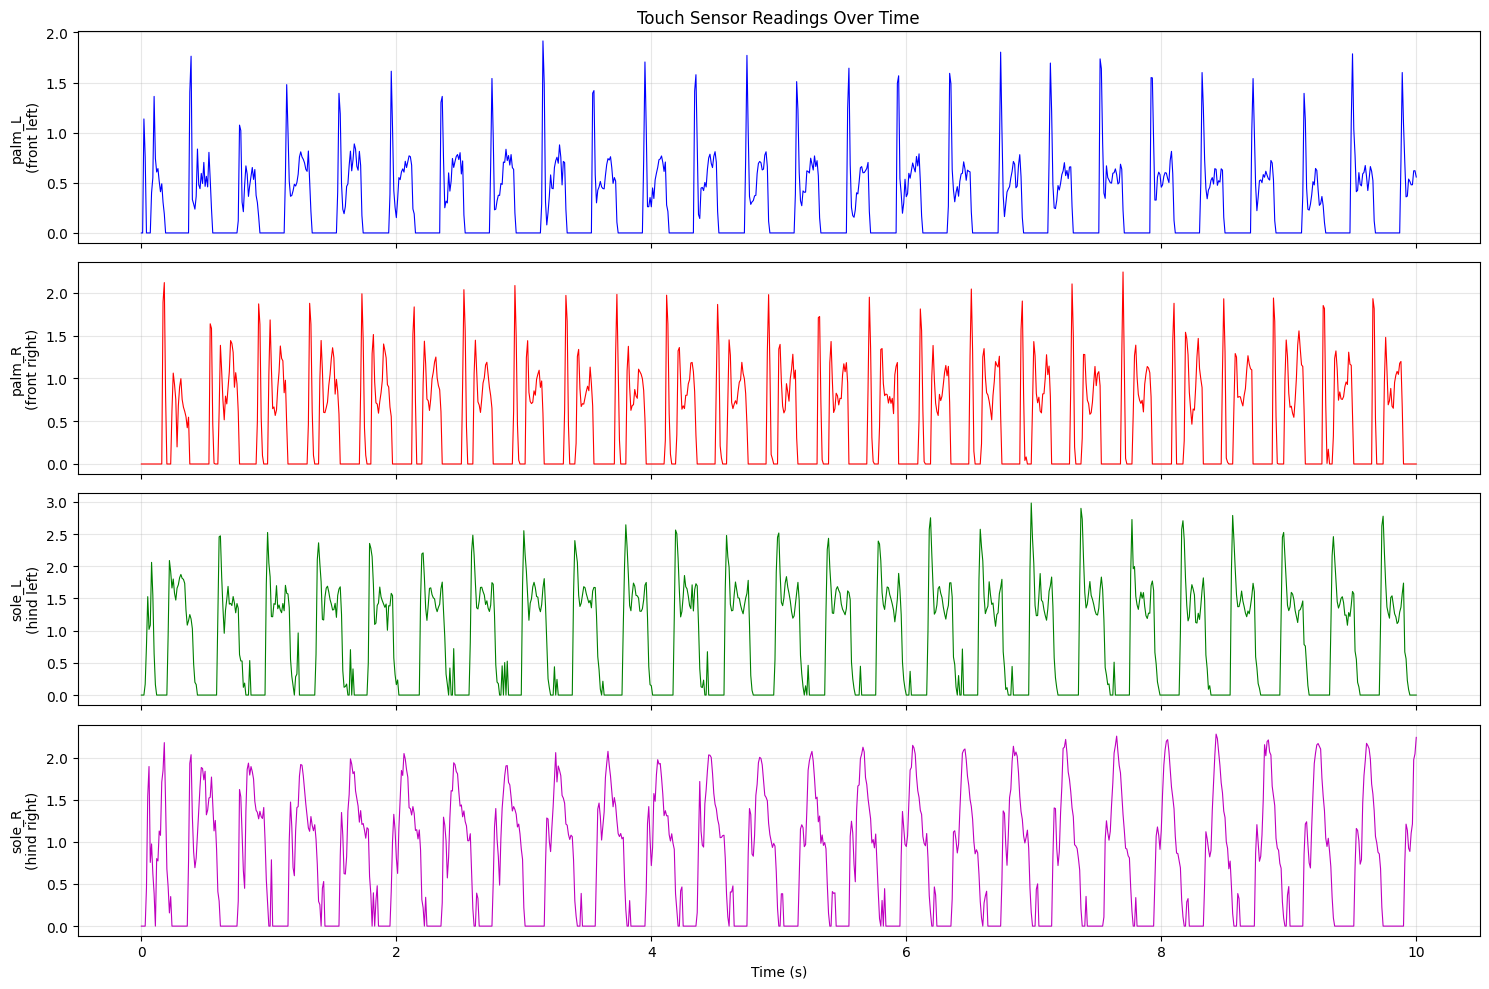

In [13]:
# Plot touch sensor data
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

timesteps = np.arange(num_timesteps)
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
time_sec = timesteps * ctrl_dt

# Palm L (front left / HL)
axes[0].plot(time_sec, palm_L_data, "b-", linewidth=0.8)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings Over Time")
axes[0].grid(True, alpha=0.3)

# Palm R (front right / HR)
axes[1].plot(time_sec, palm_R_data, "r-", linewidth=0.8)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

# Sole L (hind left / FL)
axes[2].plot(time_sec, sole_L_data, "g-", linewidth=0.8)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

# Sole R (hind right / FR)
axes[3].plot(time_sec, sole_R_data, "m-", linewidth=0.8)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "touch_sensors_full.png", dpi=300, bbox_inches="tight")
plt.show()

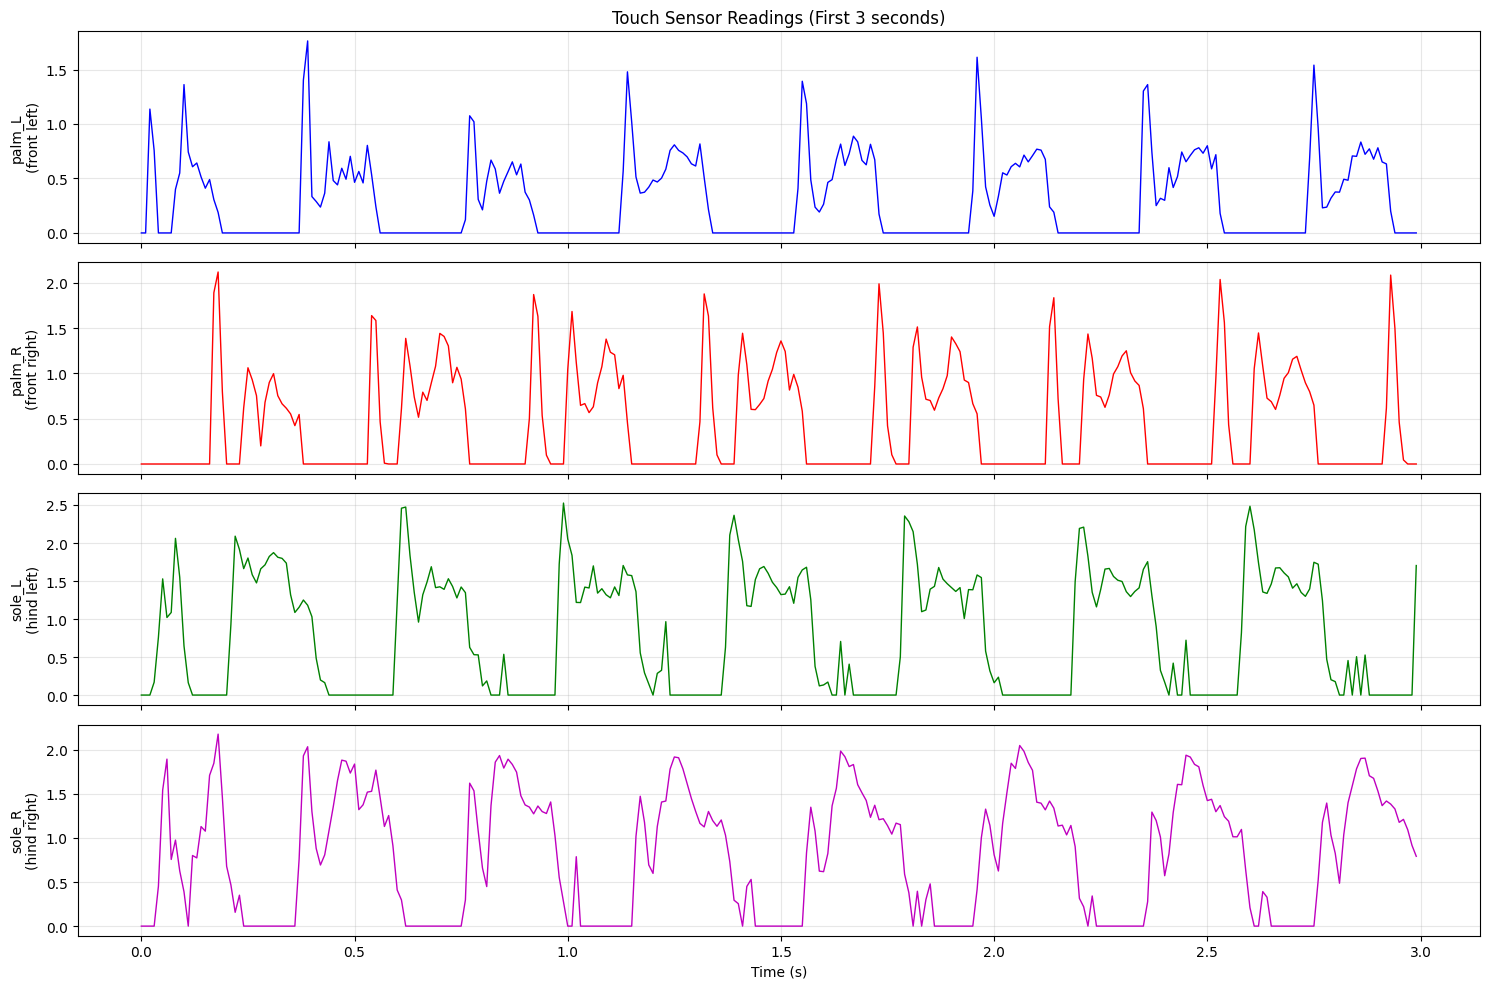

In [14]:
# Zoomed plot (first 3 seconds)
zoom_end = min(int(3.0 / ctrl_dt), num_timesteps)

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

time_zoom = time_sec[:zoom_end]

axes[0].plot(time_zoom, palm_L_data[:zoom_end], "b-", linewidth=1)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings (First 3 seconds)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_zoom, palm_R_data[:zoom_end], "r-", linewidth=1)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_zoom, sole_L_data[:zoom_end], "g-", linewidth=1)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_zoom, sole_R_data[:zoom_end], "m-", linewidth=1)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "touch_sensors_zoomed.png", dpi=300, bbox_inches="tight")
plt.show()

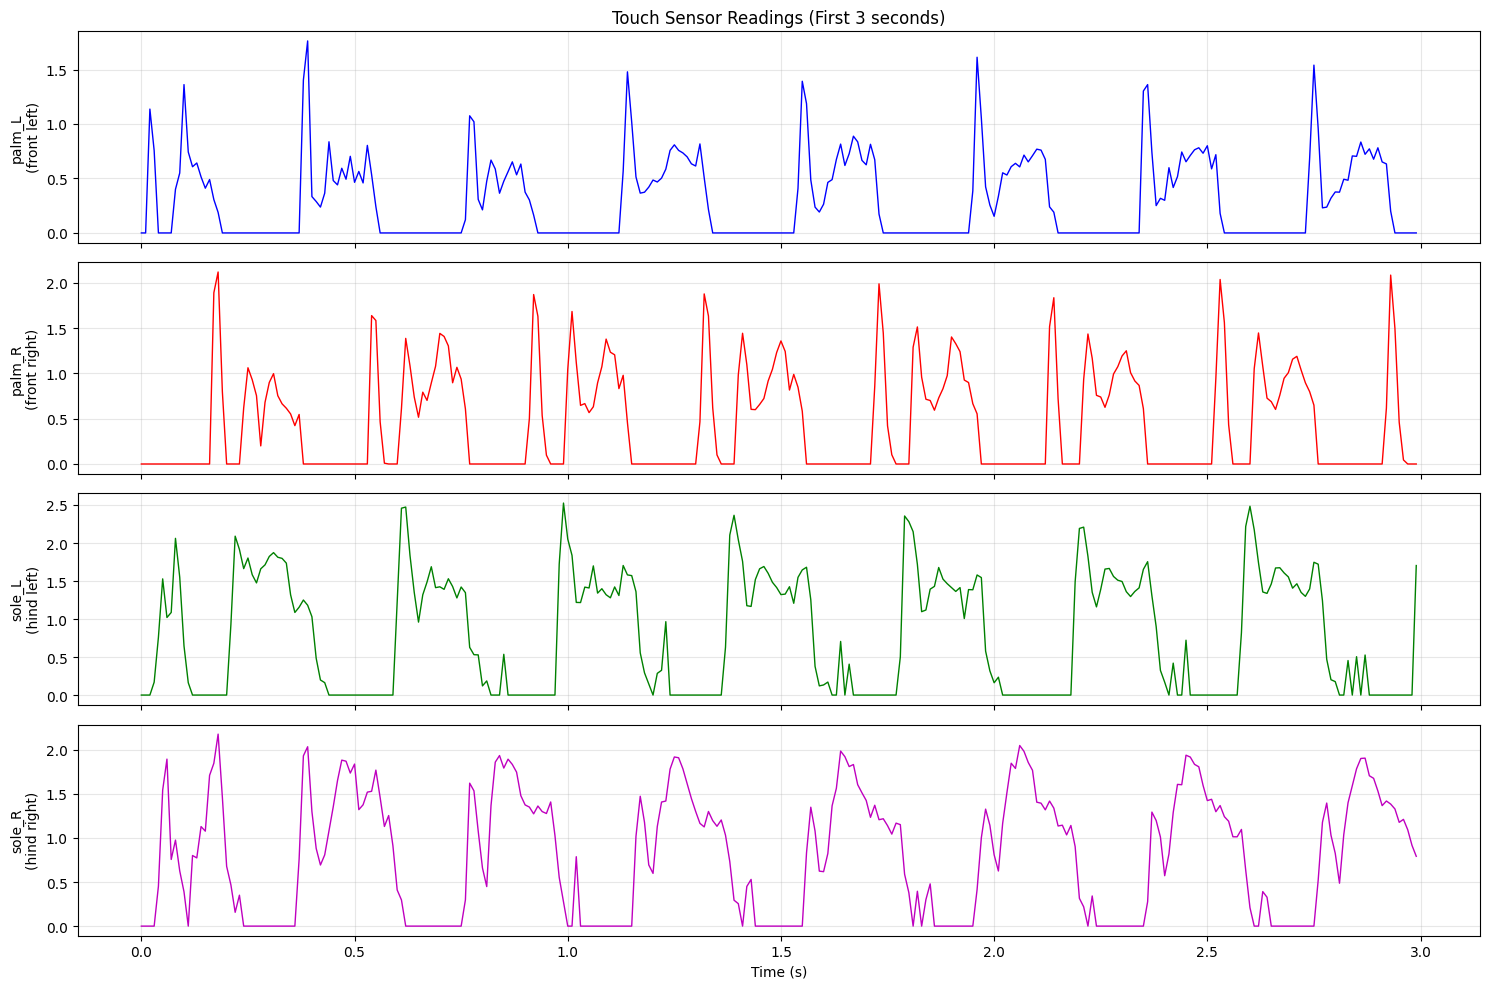

Applied median filter to raw touch sensor data


In [15]:
# Smooth raw touch sensor data in-place before thresholding
KERNEL_SIZE_PALM_L = 1
KERNEL_SIZE_PALM_R = 1
KERNEL_SIZE_SOLE_L = 1
KERNEL_SIZE_SOLE_R = 1
smooth = True

palm_L_data_smooth = medfilt(palm_L_data, kernel_size=KERNEL_SIZE_PALM_L)
palm_R_data_smooth = medfilt(palm_R_data, kernel_size=KERNEL_SIZE_PALM_R)
sole_L_data_smooth = medfilt(sole_L_data, kernel_size=KERNEL_SIZE_SOLE_L)
sole_R_data_smooth = medfilt(sole_R_data, kernel_size=KERNEL_SIZE_SOLE_R)

# Zoomed plot (first 3 seconds)
zoom_end = min(int(3.0 / ctrl_dt), num_timesteps)

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

time_zoom = time_sec[:zoom_end]

axes[0].plot(time_zoom, palm_L_data_smooth[:zoom_end], "b-", linewidth=1)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings (First 3 seconds)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_zoom, palm_R_data_smooth[:zoom_end], "r-", linewidth=1)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_zoom, sole_L_data_smooth[:zoom_end], "g-", linewidth=1)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_zoom, sole_R_data_smooth[:zoom_end], "m-", linewidth=1)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "touch_sensors_zoomed.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Applied median filter to raw touch sensor data")

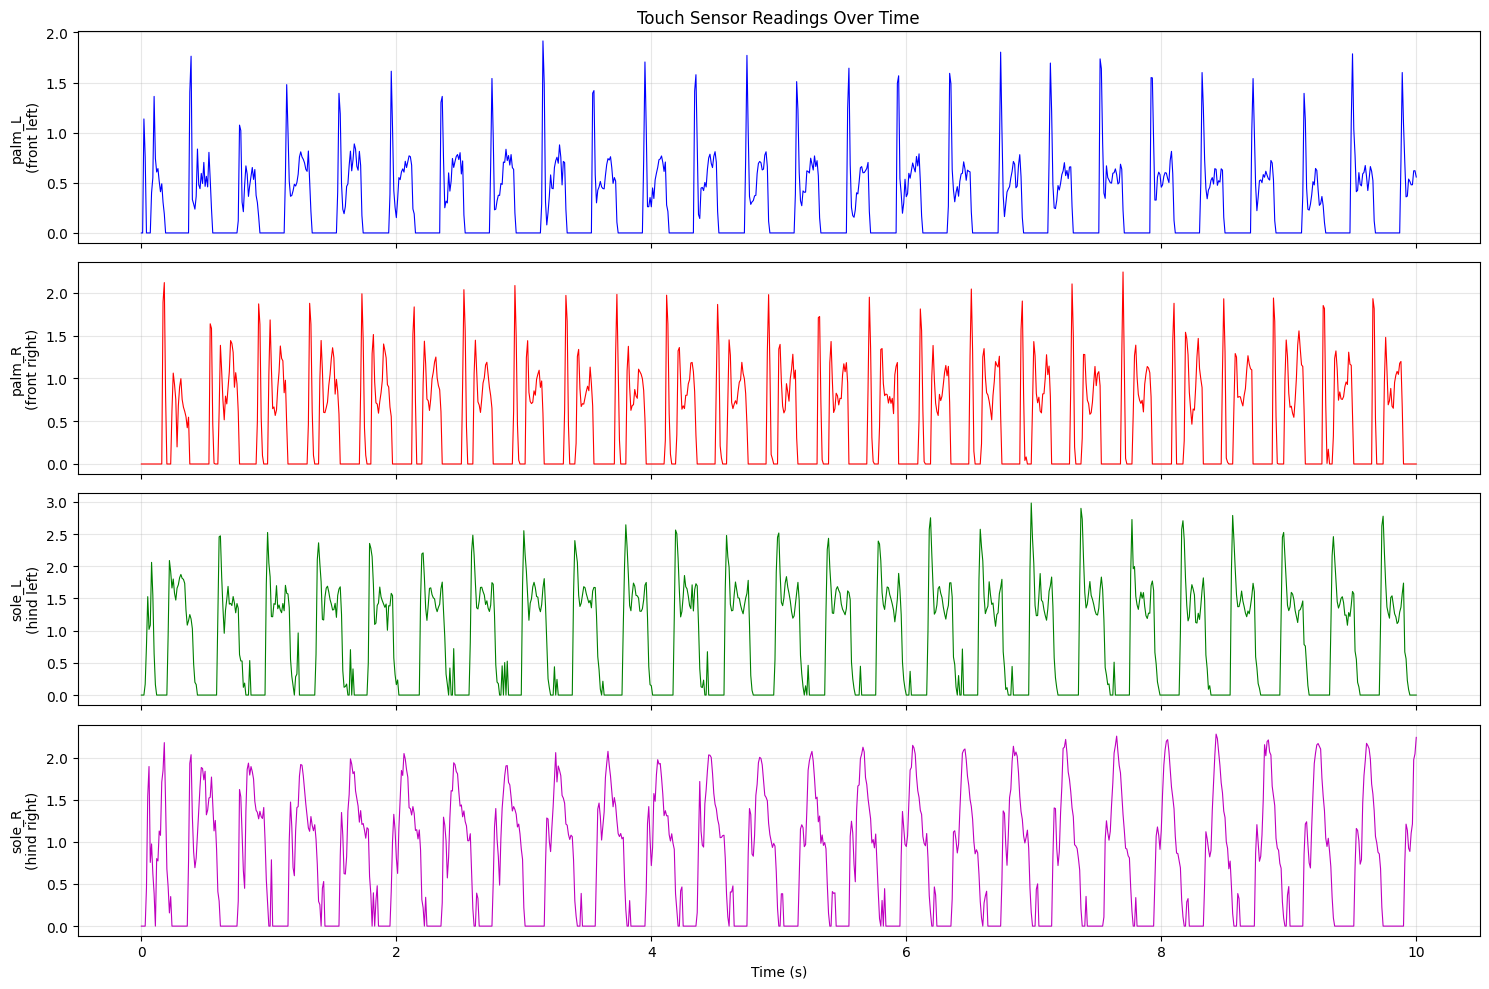

In [16]:
# Plot touch sensor data
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

timesteps = np.arange(num_timesteps)
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
time_sec = timesteps * ctrl_dt

# Palm L (front left / HL)
axes[0].plot(time_sec, palm_L_data_smooth, "b-", linewidth=0.8)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings Over Time")
axes[0].grid(True, alpha=0.3)

# Palm R (front right / HR)
axes[1].plot(time_sec, palm_R_data_smooth, "r-", linewidth=0.8)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

# Sole L (hind left / FL)
axes[2].plot(time_sec, sole_L_data_smooth, "g-", linewidth=0.8)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

# Sole R (hind right / FR)
axes[3].plot(time_sec, sole_R_data_smooth, "m-", linewidth=0.8)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "touch_sensors_full.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# Binary stance detection from touch sensors (threshold-based)
TOUCH_THRESHOLD_PALM_L = 0.01
TOUCH_THRESHOLD_PALM_R = 0.01
TOUCH_THRESHOLD_SOLE_L = 0.5
TOUCH_THRESHOLD_SOLE_R = 0.5

if smooth:
    stance_palm_L = (palm_L_data_smooth > TOUCH_THRESHOLD_PALM_L).astype(int)
    stance_palm_R = (palm_R_data_smooth > TOUCH_THRESHOLD_PALM_R).astype(int)
    stance_sole_L = (sole_L_data_smooth > TOUCH_THRESHOLD_SOLE_L).astype(int)
    stance_sole_R = (sole_R_data_smooth > TOUCH_THRESHOLD_SOLE_R).astype(int)

else:
    stance_palm_L = (palm_L_data > TOUCH_THRESHOLD_PALM_L).astype(int)
    stance_palm_R = (palm_R_data > TOUCH_THRESHOLD_PALM_R).astype(int)
    stance_sole_L = (sole_L_data > TOUCH_THRESHOLD_SOLE_L).astype(int)
    stance_sole_R = (sole_R_data > TOUCH_THRESHOLD_SOLE_R).astype(int)

# Morphological closing: fill brief gaps (swing blips) in stance bouts
from scipy.ndimage import binary_closing, binary_opening

MIN_STANCE_GAP = 10  # close gaps up to this many timesteps
do_binary_closing = True

if do_binary_closing:
    structure = np.ones(MIN_STANCE_GAP)
    stance_palm_L = binary_closing(stance_palm_L, structure=structure).astype(int)
    stance_palm_R = binary_closing(stance_palm_R, structure=structure).astype(int)
    stance_sole_L = binary_closing(stance_sole_L, structure=structure).astype(int)
    stance_sole_R = binary_closing(stance_sole_R, structure=structure).astype(int)

# Morphological opening: remove brief stance bouts shorter than threshold
MIN_STANCE_DURATION = 6  # remove stance bouts shorter than this many timesteps
do_binary_opening = False

if do_binary_opening:
    structure = np.ones(MIN_STANCE_DURATION)
    stance_palm_L = binary_opening(stance_palm_L, structure=structure).astype(int)
    stance_palm_R = binary_opening(stance_palm_R, structure=structure).astype(int)
    stance_sole_L = binary_opening(stance_sole_L, structure=structure).astype(int)
    stance_sole_R = binary_opening(stance_sole_R, structure=structure).astype(int)

# Stack into barcode format [4, timesteps]
# Order: RH, RF, LF, LH (bottom to top in plot, so LH LF RF RH top to bottom)
# LH = Left Hind = sole_L, LF = Left Front = palm_L
# RF = Right Front = palm_R, RH = Right Hind = sole_R
contact_barcode = np.stack(
    [stance_sole_R, stance_palm_R, stance_palm_L, stance_sole_L], axis=0
)

print(f"Stance percentage per limb:")
limb_labels = ["RH (sole_R)", "RF (palm_R)", "LF (palm_L)", "LH (sole_L)"]
for i, label in enumerate(limb_labels):
    stance_pct = 100 * contact_barcode[i].sum() / num_timesteps
    print(f"  {label}: {stance_pct:.1f}%")

Stance percentage per limb:
  RH (sole_R): 56.9%
  RF (palm_R): 60.0%
  LF (palm_L): 48.4%
  LH (sole_L): 57.2%


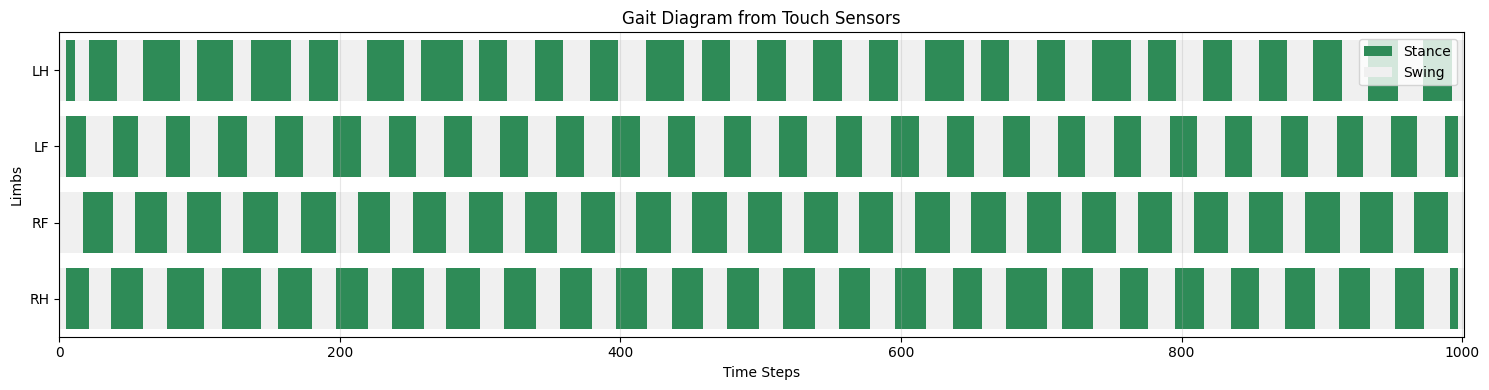

In [140]:
# Gait diagram plotting function
def plot_gait_diagram(
    contact_data,
    labels=None,
    title="Gait Diagram",
    figsize=(15, 4),
    stance_color="#2E8B57",
    swing_color="#F0F0F0",
):
    """Plot swing and stance phases for limbs over time."""
    if labels is None:
        labels = ["RH", "RF", "LF", "LH"]

    num_limbs, num_timesteps = contact_data.shape
    fig, ax = plt.subplots(figsize=figsize)

    for i, limb_label in enumerate(labels):
        # Find contiguous blocks to avoid anti-aliasing gaps between bars
        t = 0
        while t < num_timesteps:
            val = contact_data[i, t]
            color = stance_color if val == 1 else swing_color
            # Find the end of this contiguous block
            t_end = t + 1
            while t_end < num_timesteps and contact_data[i, t_end] == val:
                t_end += 1
            ax.barh(i, t_end - t, left=t, height=0.8, color=color, edgecolor="none")
            t = t_end

    ax.set_yticks(range(num_limbs))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Time Steps")
    ax.set_ylabel("Limbs")
    ax.set_title(title)
    ax.set_xlim(0, num_timesteps)
    ax.set_ylim(-0.5, num_limbs - 0.5)
    ax.grid(True, alpha=0.3, axis="x")

    stance_patch = plt.Rectangle((0, 0), 1, 1, facecolor=stance_color)
    swing_patch = plt.Rectangle((0, 0), 1, 1, facecolor=swing_color)
    ax.legend([stance_patch, swing_patch], ["Stance", "Swing"], loc="upper right")

    plt.tight_layout()
    return fig, ax


# Plot gait diagram from touch sensor stance detection
fig, ax = plot_gait_diagram(
    contact_barcode,
    labels=["RH", "RF", "LF", "LH"],
    title=f"Gait Diagram from Touch Sensors",
)
plt.savefig(OUTPUT_DIR / "gait_diagram_touch_sensors.png", dpi=300, bbox_inches="tight")
plt.show()

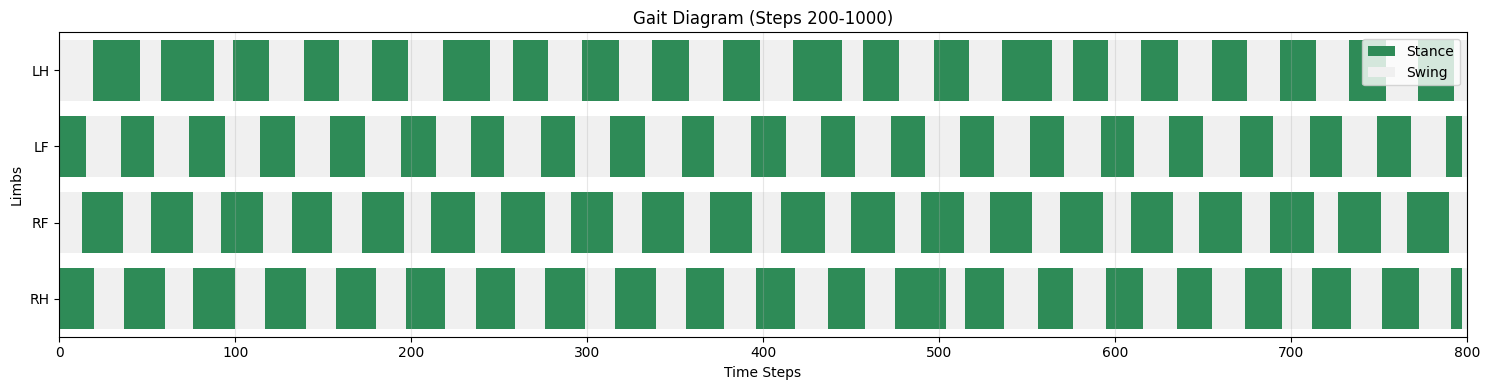

In [143]:
# Zoomed gait diagram
start_time = 200
end_time = 1000

fig, ax = plot_gait_diagram(
    contact_barcode[:, start_time:end_time],
    labels=["RH", "RF", "LF", "LH"],
    title=f"Gait Diagram (Steps {start_time}-{end_time})",
)
plt.savefig(OUTPUT_DIR / "gait_diagram_touch_zoomed.png", dpi=300, bbox_inches="tight")
plt.show()

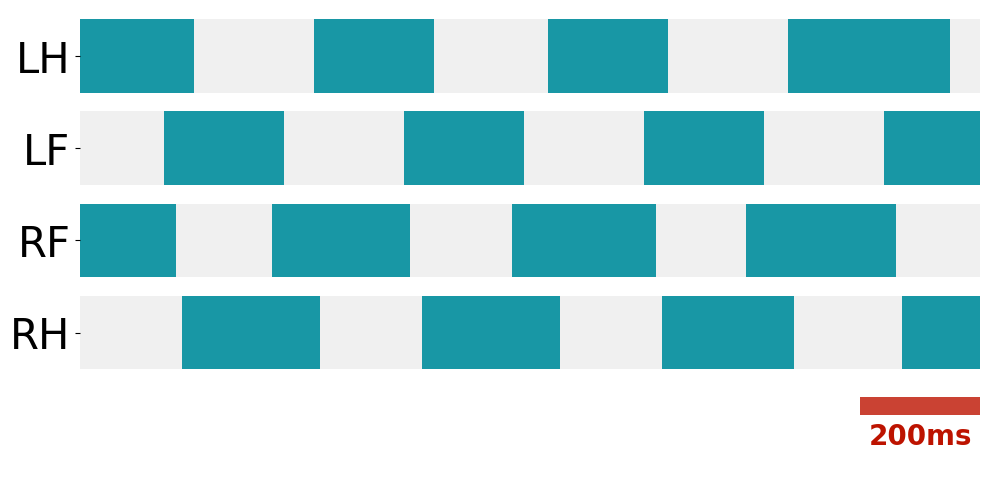

In [147]:
# Font size configuration
TICK_FONTSIZE = 30
XLABEL_FONTSIZE = 12
YLABEL_FONTSIZE = 12
TITLE_FONTSIZE = 30

# Color configuration (RGB 0-255)
STANCE_RGB = (24, 151, 165)
SCALE_BAR_RGB = (189, 19, 0)

stance_color = tuple(c / 255 for c in STANCE_RGB)
scale_bar_color = tuple(c / 255 for c in SCALE_BAR_RGB)

start_time = 300
end_time = 450
slice_len = end_time - start_time

limb_names = ["RH", "RF", "LF", "LH"]

# Plot the 4-limb gait diagram
fig, ax = plot_gait_diagram(
    contact_barcode[:, start_time:end_time],
    labels=limb_names,
    title=f"",
    figsize=(10, 5),
    stance_color=stance_color,
)
ax.get_legend().remove()

# Apply font sizes
ax.set_title(ax.get_title(), fontsize=TITLE_FONTSIZE)
ax.set_xlabel(ax.get_xlabel(), fontsize=XLABEL_FONTSIZE)
ax.set_ylabel(ax.get_ylabel(), fontsize=YLABEL_FONTSIZE)
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

# Scale bar
SCALE_BAR_TIMESTEPS = 20  # 20 timesteps = 200 ms at ctrl_dt=0.01
SCALE_BAR_LABEL = "200ms"
scale_bar_y = -0.8
scale_bar_height = 0.2
scale_bar_start = slice_len - SCALE_BAR_TIMESTEPS

ax.barh(
    scale_bar_y,
    SCALE_BAR_TIMESTEPS,
    left=scale_bar_start,
    height=scale_bar_height,
    color=scale_bar_color,
    alpha=0.8,
    edgecolor="none",
)

ax.text(
    scale_bar_start + SCALE_BAR_TIMESTEPS / 2,
    scale_bar_y - scale_bar_height / 2 - 0.08,
    SCALE_BAR_LABEL,
    ha="center",
    va="top",
    color=scale_bar_color,
    fontsize=20,
    fontweight="bold",
)

# Expand ylim to fit the scale bar and label
ax.set_ylim(scale_bar_y - 0.8, len(limb_names) - 0.5)

ax.set_ylabel("")
ax.set_xlabel("")

ax.set_xticks([])
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / f"final_gait_diagram_{NAME}.png", dpi=300, bbox_inches="tight"
)
plt.savefig(
    OUTPUT_DIR / f"final_gait_diagram_{NAME}.svg", dpi=300, bbox_inches="tight"
)
plt.savefig(
    OUTPUT_DIR / f"final_gait_diagram_{NAME}.pdf", dpi=300, bbox_inches="tight"
)
plt.show()

In [21]:
# Summary statistics
print("=" * 60)
print("Touch Sensor Gait Analysis Summary")
print("=" * 60)
print(f"\nCheckpoint: {CHECKPOINT_PATH}")
print(f"Step: {ckpt_step}")
print(f"Target speed: {env_cfg.target_speed} m/s")
print(f"Episode length: {num_timesteps} steps ({num_timesteps * ctrl_dt:.1f} s)")

print("\nStance percentages:")
limb_labels = ["RH (sole_R)", "RF (palm_R)", "LF (palm_L)", "LH (sole_L)"]
for i, label in enumerate(limb_labels):
    stance_pct = 100 * contact_barcode[i].sum() / num_timesteps
    print(f"  {label}: {stance_pct:.1f}%")

print("\nTouch sensor force statistics:")
print(f"  palm_L: mean={palm_L_data.mean():.4f}, max={palm_L_data.max():.4f}")
print(f"  palm_R: mean={palm_R_data.mean():.4f}, max={palm_R_data.max():.4f}")
print(f"  sole_L: mean={sole_L_data.mean():.4f}, max={sole_L_data.max():.4f}")
print(f"  sole_R: mean={sole_R_data.mean():.4f}, max={sole_R_data.max():.4f}")

Touch Sensor Gait Analysis Summary

Checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260209_092637_878648
Step: 2
Target speed: 0.3 m/s
Episode length: 1001 steps (10.0 s)

Stance percentages:
  RH (sole_R): 56.9%
  RF (palm_R): 60.0%
  LF (palm_L): 48.4%
  LH (sole_L): 57.2%

Touch sensor force statistics:
  palm_L: mean=0.2986, max=1.9146
  palm_R: mean=0.4623, max=2.2436
  sole_L: mean=0.8174, max=2.9824
  sole_R: mean=0.7773, max=2.2779


## Gait Cycle Detection and Metrics

Detect individual gait cycles and compute biomechanical metrics.

In [21]:
def find_gait_cycles(
    contact_barcode,
    limb_index=1,
    start_time=0,
    end_time=None,
    min_cycle_length=20,
):
    """
    Find gait cycles based on stance phase onsets.

    Args:
        contact_barcode: Shape [4, timesteps] contact data
        limb_index: Which limb to use for detection (0=RH, 1=RF, 2=LF, 3=LH)
        start_time: Start of analysis window
        end_time: End of analysis window (None = end of data)
        smooth: Whether to apply median filtering
        smooth_kernel_size: Kernel size for median filter (smaller = preserve more detail)
        smooth_limbs: List of limb indices to smooth. None = all limbs.
            Only applies smoothing to limb_index if it is in this list.
        min_cycle_length: Minimum valid cycle length in timesteps

    Returns:
        List of (cycle_start, cycle_end) tuples
    """
    if end_time is None:
        end_time = contact_barcode.shape[1]

    contacts = contact_barcode[limb_index, start_time:end_time]

    # Find stance onsets (transitions from 0 to 1)
    stance_onsets = []
    for i in range(1, len(contacts)):
        if contacts[i - 1] == 0 and contacts[i] == 1:
            stance_onsets.append(start_time + i)

    # Filter out onsets that are too close together
    filtered_onsets = []
    if len(stance_onsets) > 0:
        filtered_onsets.append(stance_onsets[0])
        for onset in stance_onsets[1:]:
            if onset - filtered_onsets[-1] >= min_cycle_length:
                filtered_onsets.append(onset)

    # Create gait cycles from consecutive stance onsets
    gait_cycles = []
    for i in range(len(filtered_onsets) - 1):
        cycle_start = filtered_onsets[i]
        cycle_end = filtered_onsets[i + 1]
        if cycle_end - cycle_start >= min_cycle_length:
            gait_cycles.append((cycle_start, cycle_end))

    return gait_cycles

In [ ]:
# Mapping from limb_index to foot body index (for xpos extraction)
# Updated to match new barcode order: [RH, RF, LF, LH]
limb_to_body_mapping = {
    0: 17,  # RH (Right Hind = sole_R) -> foot_R body
    1: 66,  # RF (Right Front = palm_R) -> hand_R body
    2: 61,  # LF (Left Front = palm_L) -> hand_L body
    3: 13,  # LH (Left Hind = sole_L) -> foot_L body
}


def compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=1,
    ctrl_dt=0.02,
):
    """
    Compute gait metrics for each gait cycle.

    Args:
        smooth_limbs: List of limb indices to smooth. None = all limbs.
            Only applies smoothing to limb_index if it is in this list.

    Returns dict with:
    - stride_length_mm: List of stride lengths in mm
    - velocity_cm_per_sec: List of velocities in cm/s
    - cadence_steps_per_min: List of cadences in steps/min (true cadence = 2x stride freq)
    - stance_percentage: List of stance percentages
    - cycle_lengths: List of cycle lengths in timesteps
    """
    foot_body_idx = limb_to_body_mapping.get(limb_index)

    metrics = {
        "stride_length_mm": [],
        "velocity_cm_per_sec": [],
        "cadence_steps_per_min": [],
        "stance_percentage": [],
        "cycle_lengths": [],
    }

    smooth_contacts = contact_barcode[limb_index, :]

    for cycle_start, cycle_end in gait_cycles:
        cycle_length = cycle_end - cycle_start
        metrics["cycle_lengths"].append(cycle_length)

        # 1. Stride Length (mm)
        if foot_body_idx is not None:
            foot_pos_start = np.array(rollout[cycle_start].data.xpos[foot_body_idx])
            foot_pos_end = np.array(rollout[cycle_end].data.xpos[foot_body_idx])
            stride_length_m = np.linalg.norm(foot_pos_end - foot_pos_start)
            stride_length_mm = stride_length_m * 1000.0
            metrics["stride_length_mm"].append(stride_length_mm)

            # 2. Velocity (cm/sec)
            cycle_duration_sec = cycle_length * ctrl_dt
            velocity_m_per_sec = stride_length_m / cycle_duration_sec
            velocity_cm_per_sec = velocity_m_per_sec * 100.0
            metrics["velocity_cm_per_sec"].append(velocity_cm_per_sec)

            # 3. Cadence (steps/min)
            # Each stride cycle = 2 steps (one per limb pair: L + R)
            stride_freq = 1.0 / cycle_duration_sec
            cadence_steps_per_min = stride_freq * 2.0 * 60.0
            metrics["cadence_steps_per_min"].append(cadence_steps_per_min)

        # 4. Stance Percentage
        cycle_contacts = smooth_contacts[cycle_start:cycle_end]
        stance_pct = 100.0 * np.sum(cycle_contacts) / len(cycle_contacts)
        metrics["stance_percentage"].append(stance_pct)

    return metrics

In [43]:
# Find gait cycles using RF (Right Front) limb
# New barcode order: 0=RH, 1=RF, 2=LF, 3=LH
gait_detection_limb = 0
analysis_start = 50  # Skip initial transient
analysis_end = 1000  # Skip final steps

gait_cycles = find_gait_cycles(
    contact_barcode,
    limb_index=gait_detection_limb,
    start_time=analysis_start,
    end_time=analysis_end,
    min_cycle_length=20,
)

print(f"Found {len(gait_cycles)} gait cycles")
for i, (start, end) in enumerate(gait_cycles[:5]):
    print(f"  Cycle {i+1}: steps {start}-{end} (length: {end-start})")
if len(gait_cycles) > 5:
    print(f"  ... and {len(gait_cycles) - 5} more cycles")

Found 23 gait cycles
  Cycle 1: steps 77-116 (length: 39)
  Cycle 2: steps 116-156 (length: 40)
  Cycle 3: steps 156-197 (length: 41)
  Cycle 4: steps 197-237 (length: 40)
  Cycle 5: steps 237-276 (length: 39)
  ... and 18 more cycles


In [44]:
# Compute gait metrics
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]

gait_metrics = compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=gait_detection_limb,
    ctrl_dt=ctrl_dt,
)

print("\nGait Metrics Summary:")
print("-" * 50)

if gait_metrics["stride_length_mm"]:
    print(
        f"Stride Length: {np.mean(gait_metrics['stride_length_mm']):.1f} +/- {np.std(gait_metrics['stride_length_mm']):.1f} mm"
    )
    print(
        f"Velocity: {np.mean(gait_metrics['velocity_cm_per_sec']):.1f} +/- {np.std(gait_metrics['velocity_cm_per_sec']):.1f} cm/s"
    )
    print(
        f"Cadence: {np.mean(gait_metrics['cadence_steps_per_min']):.1f} +/- {np.std(gait_metrics['cadence_steps_per_min']):.1f} steps/min"
    )

if gait_metrics["stance_percentage"]:
    print(
        f"Stance Percentage: {np.mean(gait_metrics['stance_percentage']):.1f} +/- {np.std(gait_metrics['stance_percentage']):.1f} %"
    )
    print(
        f"Cycle Length: {np.mean(gait_metrics['cycle_lengths']):.1f} +/- {np.std(gait_metrics['cycle_lengths']):.1f} timesteps"
    )
else:
    print("No gait cycles detected - try adjusting threshold or smoothing parameters")


Gait Metrics Summary:
--------------------------------------------------
Stride Length: 120.3 +/- 1.7 mm
Velocity: 30.3 +/- 0.5 cm/s
Cadence: 302.1 +/- 6.5 steps/min
Stance Percentage: 57.4 +/- 5.3 %
Cycle Length: 39.7 +/- 0.8 timesteps


## Summary Statistics Table

In [45]:
# Create summary table
import pandas as pd

summary_data = {
    "Metric": [],
    "Mean": [],
    "Std": [],
    "Min": [],
    "Max": [],
    "N": [],
}

metrics_info = [
    ("Stride Length (mm)", gait_metrics["stride_length_mm"]),
    ("Velocity (cm/s)", gait_metrics["velocity_cm_per_sec"]),
    ("Cadence (steps/min)", gait_metrics["cadence_steps_per_min"]),
    ("Stance Percentage (%)", gait_metrics["stance_percentage"]),
    ("Cycle Length (timesteps)", gait_metrics["cycle_lengths"]),
]

for name, values in metrics_info:
    if values:
        summary_data["Metric"].append(name)
        summary_data["Mean"].append(f"{np.mean(values):.2f}")
        summary_data["Std"].append(f"{np.std(values):.2f}")
        summary_data["Min"].append(f"{np.min(values):.2f}")
        summary_data["Max"].append(f"{np.max(values):.2f}")
        summary_data["N"].append(len(values))

summary_df = pd.DataFrame(summary_data)
print("\nGait Metrics Summary")
print("=" * 80)
print(summary_df.to_string(index=False))

# Save to CSV
summary_df.to_csv(OUTPUT_DIR / "gait_metrics_summary.csv", index=False)
print(f"\nSummary saved to: {OUTPUT_DIR / 'gait_metrics_summary.csv'}")


Gait Metrics Summary
                  Metric   Mean  Std    Min    Max  N
      Stride Length (mm) 120.29 1.70 115.76 123.60 23
         Velocity (cm/s)  30.28 0.46  29.58  31.15 23
     Cadence (steps/min) 302.11 6.48 292.68 315.79 23
   Stance Percentage (%)  57.43 5.29  51.28  72.50 23
Cycle Length (timesteps)  39.74 0.85  38.00  41.00 23

Summary saved to: /home/mila/a/aidan.sirbu/SCAMPER/data/maintain_velocity_analysis/S3e-1/gait_metrics_summary.csv


In [46]:
# Display as styled table
summary_df

,Metric,Mean,Std,Min,Max,N
0,Stride Length (mm),120.29,1.70,115.76,123.60,23
1,Velocity (cm/s),30.28,0.46,29.58,31.15,23
2,Cadence (steps/min),302.11,6.48,292.68,315.79,23
3,Stance Percentage (%),57.43,5.29,51.28,72.50,23
4,Cycle Length (timesteps),39.74,0.85,38.00,41.00,23


## Average Gait Cycle Joint Angle Profiles

Normalize each gait cycle to 0-100% and compute mean +/- std of joint angles across cycles.

In [63]:
from scipy import interpolate


def normalize_to_gait_percentage(data, cycle_length):
    """Interpolate variable-length cycle data to a standard 100-point gait percentage."""
    original_time = np.linspace(0, 100, cycle_length)
    target_time = np.linspace(0, 100, 100)
    try:
        interp_func = interpolate.interp1d(
            original_time,
            data,
            kind="cubic",
            bounds_error=False,
            fill_value="extrapolate",
        )
        return interp_func(target_time)
    except ValueError:
        interp_func = interpolate.interp1d(
            original_time,
            data,
            kind="linear",
            bounds_error=False,
            fill_value="extrapolate",
        )
        return interp_func(target_time)


# === Configuration: qpos indices and labels to analyze ===
# Forelimbs: Shoulder-L(61), Shoulder-R(69), Elbow-L(63), Elbow-R(71)
# Hindlimbs: Hip-L(15), Hip-R(21), Knee-L(16), Knee-R(22)
QPOS_INDICES = [15, 21, 16, 22, 17, 23, 61, 69, 63, 71]
QPOS_LABELS = {
    15: "Hip-L",
    21: "Hip-R",
    16: "Knee-L",
    22: "Knee-R",
    17: "Ankle-L",
    23: "Ankle-R",
    61: "Shoulder-L",
    69: "Shoulder-R",
    63: "Elbow-L",
    71: "Elbow-R",
}
CONVERT_TO_DEGREES = True

# === Phase offsets per qpos index (0-100%, circular shift of the gait cycle) ===
# e.g. 50 means the cycle is shifted by half a period.
# Joints not listed default to 0 (no shift).
PHASE_OFFSETS = {
    # 16: 10,
    # 15: 10,
    # 21: 50,  # Hip-R: shift 50% to align with Hip-L
    # 22: 50,  # Knee-R
    # 23: 50,  # Ankle-R
    # 69: 50,  # Shoulder-R
    # 71: 50,  # Elbow-R
}

# Extract qpos timeseries from rollout (shape: [timesteps, n_qpos])
qpos_all = np.array([np.array(state.data.qpos) for state in rollout])
print(f"Extracted qpos: shape {qpos_all.shape}")

# Collect normalised cycles for every joint
joint_cycle_data = {idx: [] for idx in QPOS_INDICES}

for cycle_start, cycle_end in gait_cycles:
    cycle_length = cycle_end - cycle_start
    for qpos_idx in QPOS_INDICES:
        segment = qpos_all[cycle_start:cycle_end, qpos_idx]
        normalised = normalize_to_gait_percentage(segment, cycle_length)
        # Apply phase offset (circular roll on the 100-point array)
        shift = PHASE_OFFSETS.get(qpos_idx, 0)
        if shift != 0:
            normalised = np.roll(normalised, int(round(shift)))
        joint_cycle_data[qpos_idx].append(normalised)

# Compute mean and std across cycles
joint_cycle_stats = {}
for qpos_idx in QPOS_INDICES:
    cycles_arr = np.array(joint_cycle_data[qpos_idx])  # (n_cycles, 100)
    if CONVERT_TO_DEGREES:
        cycles_arr = np.degrees(cycles_arr)
    joint_cycle_stats[qpos_idx] = {
        "mean": np.mean(cycles_arr, axis=0),
        "std": np.std(cycles_arr, axis=0),
        "n_cycles": len(joint_cycle_data[qpos_idx]),
        "raw_cycles": cycles_arr,
    }

n_cycles = joint_cycle_stats[QPOS_INDICES[0]]["n_cycles"]
print(f"Averaged {n_cycles} gait cycles across {len(QPOS_INDICES)} joints")
if any(v != 0 for v in PHASE_OFFSETS.values()):
    print(
        f"Phase offsets applied: { {QPOS_LABELS.get(k, k): v for k, v in PHASE_OFFSETS.items() if v != 0} }"
    )

Extracted qpos: shape (1001, 74)
Averaged 23 gait cycles across 10 joints


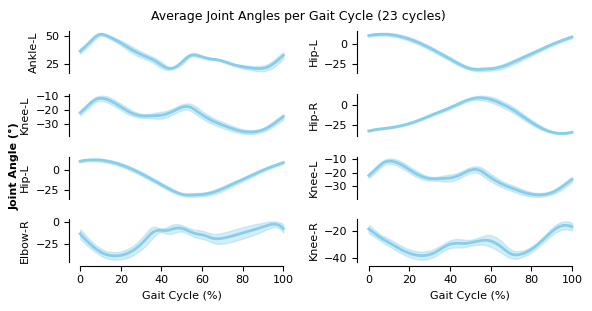

In [65]:
# Plot average gait cycle joint angle profiles (2-column: forelimbs | hindlimbs)
forelimb_indices = [17, 16, 15, 71]
forelimb_titles = ["Ankle-L", "Knee-L", "Hip-L", "Elbow-R"]

hindlimb_indices = [15, 21, 16, 22]
hindlimb_titles = ["Hip-L", "Hip-R", "Knee-L", "Knee-R"]

all_indices = [forelimb_indices, hindlimb_indices]
all_titles = [forelimb_titles, hindlimb_titles]

n_rows = max(len(forelimb_indices), len(hindlimb_indices))
fig, axes = plt.subplots(n_rows, 2, figsize=(6, 3), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = "#87CEEB"
rollout_shade_alpha = 0.35

for col in range(2):
    joint_indices = all_indices[col]
    joint_titles = all_titles[col]

    for row, (qpos_idx, joint_title) in enumerate(zip(joint_indices, joint_titles)):
        ax = axes[row, col]

        if qpos_idx in joint_cycle_stats:
            stats = joint_cycle_stats[qpos_idx]
            mean = stats["mean"]
            std = stats["std"]

            ax.plot(gait_percentage, mean, color=rollout_color, linewidth=2)
            ax.fill_between(
                gait_percentage,
                mean - std,
                mean + std,
                color=rollout_color,
                alpha=rollout_shade_alpha,
            )

        ax.set_ylabel(joint_title, fontsize=8)
        ax.grid(False)
        ax.tick_params(axis="both", which="major", labelsize=8)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if row < n_rows - 1:
            ax.spines["bottom"].set_visible(False)
            ax.tick_params(bottom=False, labelbottom=False)
            ax.spines["left"].set_position(("outward", 1))
        else:
            ax.spines["bottom"].set_bounds(0, 100)
            ax.spines["left"].set_position(("outward", 1))
            ax.spines["bottom"].set_position(("outward", 3))
            ax.set_xlabel("Gait Cycle (%)", fontsize=8)

angle_unit = "\u00b0" if CONVERT_TO_DEGREES else "rad"
fig.text(
    0.02,
    0.5,
    f"Joint Angle ({angle_unit})",
    va="center",
    rotation="vertical",
    fontsize=8,
    fontweight="bold",
)

n = joint_cycle_stats[forelimb_indices[0]]["n_cycles"]
fig.suptitle(f"Average Joint Angles per Gait Cycle ({n} cycles)", fontsize=9, y=1.02)

plt.tight_layout()
plt.subplots_adjust(left=0.12, top=0.95)
plt.savefig(OUTPUT_DIR / "joint_angle_avg_gait_cycle.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Plot average gait cycle profiles for left hip (2 DOFs), knee, and ankle
# Hip DOF qpos indices: abduct=14, extend=15, knee=16, ankle=17

# Y-axis limits for each joint (degrees). Set to None for auto-scaling.
Y_LIMITS = {
    15: None,       # Hip Flexion
    14: (-40, 20),  # Hip Adduction
    16: None,       # Knee Flexion
    17: None,       # Ankle Dorsiflexion
}

# Font / line styling (matched to plot_kid_results.ipynb)
LABEL_FONTSIZE = 20
TICK_LABELSIZE = 16
TICK_WIDTH = 2
TICK_LENGTH = 6
SPINE_WIDTH = 2

hip_extra_indices = [14]
for qpos_idx in hip_extra_indices:
    if qpos_idx not in joint_cycle_stats:
        cycles = []
        for cycle_start, cycle_end in gait_cycles:
            segment = qpos_all[cycle_start:cycle_end, qpos_idx]
            normalised = normalize_to_gait_percentage(segment, cycle_end - cycle_start)
            shift = PHASE_OFFSETS.get(qpos_idx, 0)
            if shift != 0:
                normalised = np.roll(normalised, int(round(shift)))
            cycles.append(normalised)
        cycles_arr = np.array(cycles)
        if CONVERT_TO_DEGREES:
            cycles_arr = np.degrees(cycles_arr)
        joint_cycle_stats[qpos_idx] = {
            "mean": np.mean(cycles_arr, axis=0),
            "std": np.std(cycles_arr, axis=0),
            "n_cycles": len(cycles),
            "raw_cycles": cycles_arr,
        }

left_indices = [15, 14, 16, 17]
left_titles = [
    "Hip Flexion",
    "Hip Adduction",
    "Knee Flexion",
    "Ankle Dorsiflexion",
]

n_rows = len(left_indices)
fig, axes = plt.subplots(n_rows, 1, figsize=(3, 5), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = tuple(c / 255 for c in (0, 170, 188))
rollout_shade_alpha = 0.35

for row, (qpos_idx, joint_title) in enumerate(zip(left_indices, left_titles)):
    ax = axes[row]
    stats = joint_cycle_stats[qpos_idx]
    mean = stats["mean"]
    std = stats["std"]

    ax.plot(gait_percentage, mean, color=rollout_color, linewidth=2)
    ax.fill_between(
        gait_percentage,
        mean - std,
        mean + std,
        color=rollout_color,
        alpha=rollout_shade_alpha,
    )

    if Y_LIMITS.get(qpos_idx) is not None:
        ax.set_ylim(*Y_LIMITS[qpos_idx])
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(10))

    ax.set_ylabel(joint_title, fontsize=LABEL_FONTSIZE)
    ax.yaxis.set_label_coords(-0.22, 0.5)  # align all y-labels at same x
    ax.tick_params(axis="both", which="major", labelsize=TICK_LABELSIZE,
                   width=TICK_WIDTH, length=TICK_LENGTH)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(SPINE_WIDTH)
    ax.grid(False)

    if row < n_rows - 1:
        ax.spines["bottom"].set_visible(False)
        ax.tick_params(bottom=False, labelbottom=False)
        ax.spines["left"].set_position(("outward", 1))
    else:
        ax.spines["bottom"].set_bounds(0, 100)
        ax.spines["left"].set_position(("outward", 1))
        ax.spines["bottom"].set_position(("outward", 3))
        ax.set_xlabel("Gait Cycle (%)", fontsize=LABEL_FONTSIZE)

angle_unit = "\u00b0" if CONVERT_TO_DEGREES else "rad"
fig.text(
    -0.08,
    0.5,
    f"Joint Angle ({angle_unit})",
    va="center",
    rotation="vertical",
    fontsize=LABEL_FONTSIZE,
    fontweight="bold",
)

n = joint_cycle_stats[left_indices[0]]["n_cycles"]
fig.suptitle(
    f"Left Hindlimb Joint Angles per Gait Cycle ({n} cycles)", fontsize=9, y=1.02
)

plt.tight_layout()
plt.subplots_adjust(left=0.22, top=0.95)
plt.savefig(
    OUTPUT_DIR / "joint_angle_avg_gait_cycle_left_hindlimb.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

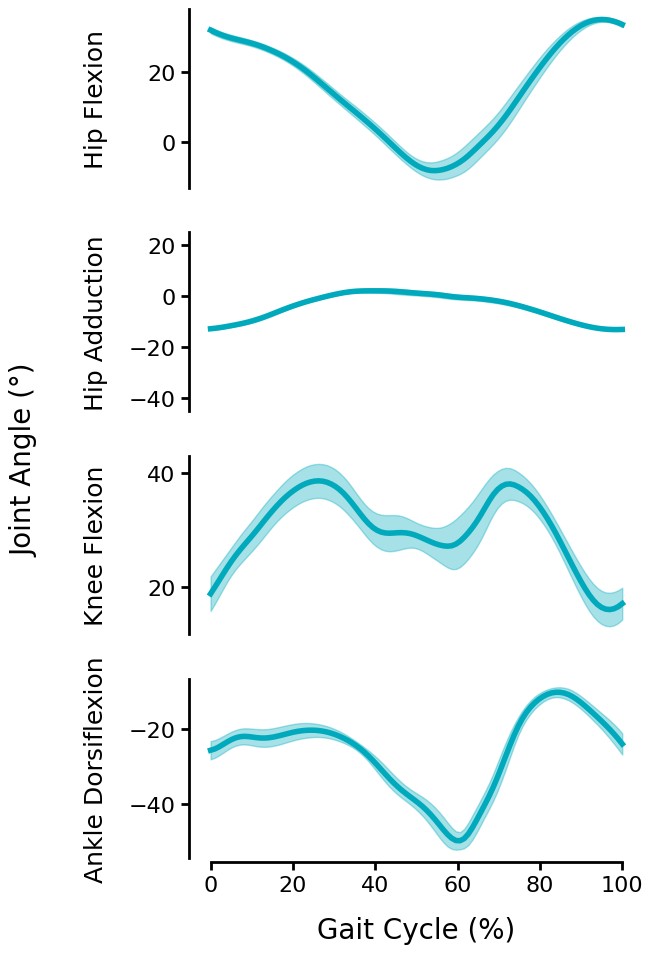

In [148]:
# Plot average gait cycle profiles for right hip (2 DOFs), knee, and ankle
# Hip DOF qpos indices: abduct=20, extend=21, knee=22, ankle=23
#
# NOTE: Right-leg angles are negated to match left-leg / standard anatomical
# convention. This is necessary because the MuJoCo XML defines right-leg joint
# axes with opposite signs to the left leg for bilateral symmetry, e.g.:
#   hip_L_abduct   axis=( 1, 0,  0)  vs  hip_R_abduct   axis=(-1, 0, 0)
#   knee_L         axis=( 0.5,-1, 0)  vs  knee_R         axis=(-0.5,-1, 0)
#   ankle_L        axis=(-0.3, 1, 0)  vs  ankle_R        axis=( 0.3, 1, 0)
NEGATE_RIGHT = True

# Y-axis limits for each joint (degrees). Set to None for auto-scaling.
Y_LIMITS = {
    21: None,       # Hip Flexion
    20: (-45, 25),  # Hip Adduction
    22: None,       # Knee Flexion
    23: None,       # Ankle Dorsiflexion
}

# Font / line styling (matched to plot_kid_results.ipynb)
LABEL_FONTSIZE = 20
JOINTNAME_FONTSIZE = 18
TICK_LABELSIZE = 16
TICK_WIDTH = 2
TICK_LENGTH = 6
SPINE_WIDTH = 2

hip_extra_indices_R = [20]
for qpos_idx in hip_extra_indices_R:
    if qpos_idx not in joint_cycle_stats:
        cycles = []
        for cycle_start, cycle_end in gait_cycles:
            segment = qpos_all[cycle_start:cycle_end, qpos_idx]
            normalised = normalize_to_gait_percentage(segment, cycle_end - cycle_start)
            shift = PHASE_OFFSETS.get(qpos_idx, 0)
            if shift != 0:
                normalised = np.roll(normalised, int(round(shift)))
            cycles.append(normalised)
        cycles_arr = np.array(cycles)
        if CONVERT_TO_DEGREES:
            cycles_arr = np.degrees(cycles_arr)
        joint_cycle_stats[qpos_idx] = {
            "mean": np.mean(cycles_arr, axis=0),
            "std": np.std(cycles_arr, axis=0),
            "n_cycles": len(cycles),
            "raw_cycles": cycles_arr,
        }

right_indices = [21, 20, 22, 23]
right_titles = [
    "Hip Flexion",
    "Hip Adduction",
    "Knee Flexion",
    "Ankle Dorsiflexion",
]

n_rows = len(right_indices)
fig, axes = plt.subplots(n_rows, 1, figsize=(6, 10), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = tuple(c / 255 for c in (0, 170, 188))
rollout_shade_alpha = 0.35
global_sign = -1.0 if NEGATE_RIGHT else 1.0

for row, (qpos_idx, joint_title) in enumerate(zip(right_indices, right_titles)):
    ax = axes[row]
    stats = joint_cycle_stats[qpos_idx]
    mean = global_sign * stats["mean"]
    std = stats["std"]

    ax.plot(gait_percentage, mean, color=rollout_color, linewidth=4)
    ax.fill_between(
        gait_percentage,
        mean - std,
        mean + std,
        color=rollout_color,
        alpha=rollout_shade_alpha,
    )

    if Y_LIMITS.get(qpos_idx) is not None:
        ax.set_ylim(*Y_LIMITS[qpos_idx])
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))

    ax.set_ylabel(joint_title, fontsize=JOINTNAME_FONTSIZE)
    ax.yaxis.set_label_coords(-0.18, 0.5)  # align all y-labels at same x
    ax.tick_params(axis="both", which="major", labelsize=TICK_LABELSIZE,
                   width=TICK_WIDTH, length=TICK_LENGTH)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(SPINE_WIDTH)
    ax.grid(False)

    if row < n_rows - 1:
        ax.spines["bottom"].set_visible(False)
        ax.tick_params(bottom=False, labelbottom=False)
        ax.spines["left"].set_position(("outward", 1))
    else:
        ax.spines["bottom"].set_bounds(0, 100)
        ax.spines["left"].set_position(("outward", 1))
        ax.spines["bottom"].set_position(("outward", 3))
        ax.set_xlabel("Gait Cycle (%)", fontsize=LABEL_FONTSIZE, labelpad=15)

angle_unit = "\u00b0" if CONVERT_TO_DEGREES else "rad"
fig.text(
    -0.08,
    0.5,
    f"Joint Angle ({angle_unit})",
    va="center",
    rotation="vertical",
    fontsize=LABEL_FONTSIZE,
)

n = joint_cycle_stats[right_indices[0]]["n_cycles"]

plt.tight_layout()
plt.subplots_adjust(left=0.22, top=0.95, hspace=0.25)
plt.savefig(
    OUTPUT_DIR / "joint_angle_avg_gait_cycle_right_hindlimb.png",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    OUTPUT_DIR / "joint_angle_avg_gait_cycle_right_hindlimb.pdf",
    dpi=300,
    bbox_inches="tight",
)
plt.savefig(
    OUTPUT_DIR / "joint_angle_avg_gait_cycle_right_hindlimb.svg",
    dpi=300,
    bbox_inches="tight",
)
plt.show()